In [1]:
# Step 1 is loading libraries
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import re
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('gutenberg')
nltk.download('averaged_perceptron_tagger_eng')
# This is a terminal command
!python -m spacy download en_core_web_sm

nlp = spacy.load("en_core_web_sm")

print("Libraries loaded successfully!")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     - -------------------------------------- 0.5/12.8 MB 1.9 MB/s eta 0:00:07
     --- ------------------------------------ 1.0/12.8 MB 2.5 MB/s eta 0:00:05
     --- ------------------------------------ 1.0/12.8 MB 2.5 MB/s eta 0:00:05
     ----- ---------------------------------- 1.8/12.8 MB 2.2 MB/s eta 0:00:05
     -------- ------------------------------- 2.6/12.8 MB 2.5 MB/s eta 0:00:05
     --------- ------------------------------ 3.1/12.8 MB 2.5 MB/s eta 0:00:04
     ----------- ---------------------------- 3.7/12.8 MB 2.6 MB/s eta 0:00:04
     ------------- -------------------------- 4.5/12.8 MB 2.7 MB/s eta 0:00:04
     --------------- ------------------------ 5.0/12.8 MB 2.6 MB/s eta 0:00:03
     --------------- ------------------------ 5.0/12.8 MB 2.6 MB/s eta 0:

In [5]:
# Step 2 is loading the text file
with open("moby_dick.txt", "r", encoding="utf-8") as file:
    raw_text = file.read()

print("Original character count:", len(raw_text))
print(raw_text[:500])

Original character count: 1238311
The Project Gutenberg eBook of Moby Dick; Or, The Whale
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBo


In [6]:
text = raw_text
# Start from Chapter 1.
match = re.search(
    r'CHAPTER\s+1\.\s*Loomings\.',
    text,
    flags=re.IGNORECASE
)

if match:
    text = text[match.start():]
else:
    print("Chapter 1 heading not found. Check the text format.")

text = re.split(
    r'\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*',
    text,
    maxsplit=1,
    flags=re.IGNORECASE | re.DOTALL
)[0]

text = re.sub(
    r'(?im)^\s*CHAPTER\s+[IVXLCDM\d]+\s*\.\s*.*$',
    '',
    text
)

text = re.sub(r'\b\d+\b', '', text)

text = re.sub(r'\[Illustration[^\]]*\]', '', text, flags=re.IGNORECASE)

text = re.sub(r'\s+', ' ', text).strip()

print("Cleaned character count:", len(text))
print("\nCleaned text preview:\n")
print(text[:1000])

Cleaned character count: 1206230

Cleaned text preview:

Pictures of Whaling Scenes. Stone; in Mountains; in Stars. over Him. Epilogue Original Transcriber’s Notes: This text is a combination of etexts, one from the now-defunct ERIS project at Virginia Tech and one from Project Gutenberg’s archives. The proofreaders of this version are indebted to The University of Adelaide Library for preserving the Virginia Tech version. The resulting etext was compared with a public domain hard copy version of the text. ETYMOLOGY. (Supplied by a Late Consumptive Usher to a Grammar School.) The pale Usher—threadbare in coat, heart, body, and brain; I see him now. He was ever dusting his old lexicons and grammars, with a queer handkerchief, mockingly embellished with all the gay flags of all the known nations of the world. He loved to dust his old grammars; it somehow mildly reminded him of his mortality. “While you take in hand to school others, and to teach them by what name a whale-fish is to be ca

In [7]:
# NLTK tokenization
nlp.max_length = 2_000_000
nltk_tokens = nltk.word_tokenize(text)

# spaCy tokenization
doc = nlp(text)
spacy_tokens = [token.text for token in doc]

print("NLTK token count:", len(nltk_tokens))
print("spaCy token count:", len(spacy_tokens))

NLTK token count: 257248
spaCy token count: 258519


In [8]:
examples = [
    "Ishmael's journey",
    "don't stop",
    "the sea—dark and cold.",
    "Ahab's ship"
]

for example in examples:
    print("\nText:", example)
    print("NLTK:", nltk.word_tokenize(example))
    print("spaCy:", [token.text for token in nlp(example)])


Text: Ishmael's journey
NLTK: ['Ishmael', "'s", 'journey']
spaCy: ['Ishmael', "'s", 'journey']

Text: don't stop
NLTK: ['do', "n't", 'stop']
spaCy: ['do', "n't", 'stop']

Text: the sea—dark and cold.
NLTK: ['the', 'sea', '—', 'dark', 'and', 'cold', '.']
spaCy: ['the', 'sea', '—', 'dark', 'and', 'cold', '.']

Text: Ahab's ship
NLTK: ['Ahab', "'s", 'ship']
spaCy: ['Ahab', "'s", 'ship']


In [9]:
# Count POS tags
pos_counts = Counter(
    token.pos_ for token in doc
    if not token.is_space
)

# We can write our values in a dataframe by using pandas
pos_table = pd.DataFrame(
    pos_counts.most_common(),
    columns=["POS Tag", "Count"]
)

print(pos_table.to_string(index=False))

POS Tag  Count
   NOUN  42941
  PUNCT  40740
    ADP  26929
   VERB  26347
    DET  24964
   PRON  21276
    ADJ  17974
    ADV  14442
    AUX  10728
  PROPN   9299
  CCONJ   9239
  SCONJ   5986
   PART   4930
    NUM   2037
   INTJ    590
      X     94
    SYM      3


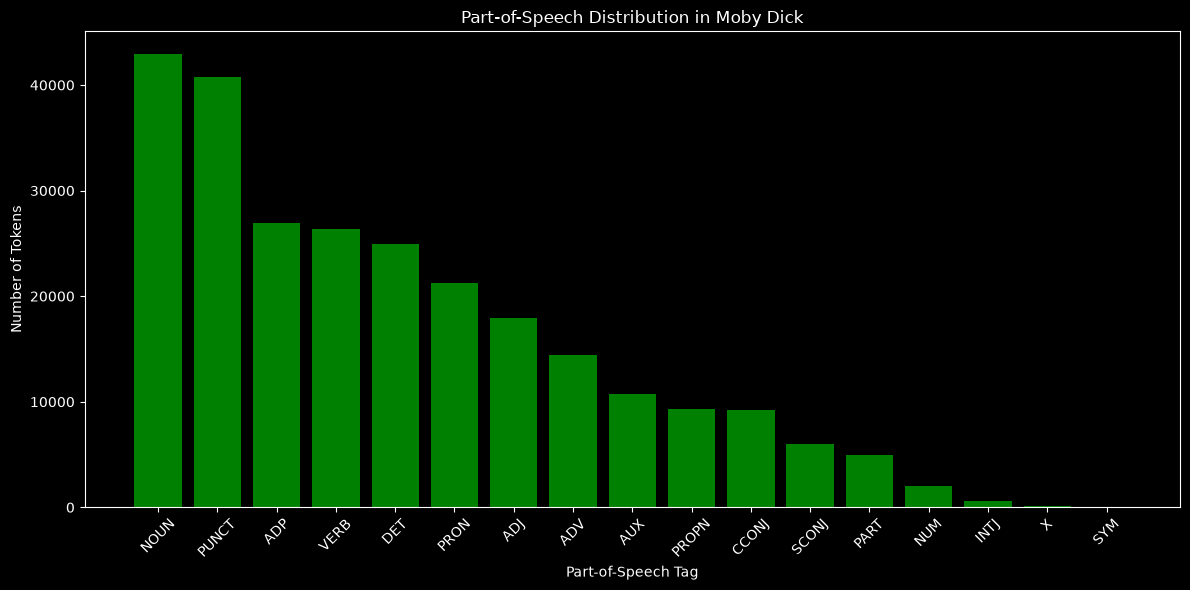

In [10]:
#For data visualization, let's use matplotlib
plt.figure(figsize=(12, 6))

plt.bar(pos_table["POS Tag"], pos_table["Count"], color="green")
plt.title("Part-of-Speech Distribution in Moby Dick")
plt.xlabel("Part-of-Speech Tag")
plt.ylabel("Number of Tokens")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Five most common noun lemmas
noun_counts = Counter(
    token.lemma_.lower()
    for token in doc
    if token.pos_ == "NOUN" and token.is_alpha
)

print("Top 5 nouns:")
print(pd.DataFrame(
    noun_counts.most_common(5),
    columns=["Noun Lemma", "Frequency"]
).to_string(index=False))


# Five most common verb lemmas
verb_counts = Counter(
    token.lemma_.lower()
    for token in doc
    if token.pos_ == "VERB" and token.is_alpha
)

print("\nTop 5 verbs:")
print(pd.DataFrame(
    verb_counts.most_common(5),
    columns=["Verb Lemma", "Frequency"]
).to_string(index=False))

Top 5 nouns:
Noun Lemma  Frequency
     whale       1121
       man        745
      ship        593
       sea        509
      boat        477

Top 5 verbs:
Verb Lemma  Frequency
       say        601
       see        571
      have        550
        go        480
      seem        449


In [13]:
# Counting plural nouns
plural_nouns = [
    token.lemma_.lower()
    for token in doc
    if token.pos_ == "NOUN"
    and (
        token.morph.get("Number") == ["Plur"]
        or token.tag_ == "NNS"
    )
    and token.is_alpha
]

print("Total plural noun occurrences:", len(plural_nouns))

print("\nTop 10 plural nouns:")
print(pd.DataFrame(
    Counter(plural_nouns).most_common(10),
    columns=["Plural Noun Lemma", "Frequency"]
).to_string(index=False))

Total plural noun occurrences: 10604

Top 10 plural nouns:
Plural Noun Lemma  Frequency
            whale        242
              man        239
              eye        156
             boat        145
            thing        131
             foot        127
             hand        123
               ye        113
             time        112
             year         95


In [14]:
# Total past tense verbs that are stemmed
past_verbs = [
    token.lemma_.lower()
    for token in doc
    if token.tag_ == "VBD" and token.is_alpha
]

print("Total past-tense verb occurrences:", len(past_verbs))

print("\nTop 10 past-tense verbs:")
print(pd.DataFrame(
    Counter(past_verbs).most_common(10),
    columns=["Verb Lemma", "Frequency"]
).to_string(index=False))

Total past-tense verb occurrences: 8636

Top 10 past-tense verbs:
Verb Lemma  Frequency
        be       2330
      have        758
        do        290
      seem        263
       say        258
       cry        150
      come        124
       see        120
     think         94
        go         94


In [15]:
# Finding Superlative adjectives
superlatives = [
    (token.text, token.lemma_.lower())
    for token in doc
    if token.tag_ == "JJS"
]

superlative_table = pd.DataFrame(
    superlatives,
    columns=["Superlative Adjective", "Lemma"]
).drop_duplicates()

print(superlative_table.to_string(index=False))
print("\nTotal unique superlative adjectives:", len(superlative_table))

Superlative Adjective      Lemma
                least      least
            belongest     belong
                 most       most
              biggest        big
                 best       good
         sovereignest  sovereign
              largest      large
              boldest       bold
            extremest    extreme
              deepest       deep
            dreamiest     dreamy
             shadiest      shady
             quietest      quiet
              tallest       tall
             cheapest      cheap
            cheeriest     cheery
            observest     observ
            reasonest     reason
               latest       late
            arrantest     arrant
               finest       fine
              highest       high
              longest       long
             greatest      great
            strangest    strange
            slightest     slight
             queerest      queer
              tempest       temp
              dearest       dear
          

In [16]:
# Passive voice
passive_examples = []

for sent in doc.sents:
    for token in sent:
        # Support common spaCy dependency labels
        if token.dep_ in ("nsubjpass", "nsubj:pass"):
            verb = token.head

            # Look for a form of "be" among the auxiliaries
            has_be = any(
                child.lemma_.lower() == "be"
                and child.dep_ in ("aux", "auxpass", "aux:pass")
                for child in verb.children
            )

            if has_be:
                passive_examples.append({
                    "Passive Subject": token.text,
                    "Verb": verb.text,
                    "Sentence Context": sent.text.strip()
                })

passive_table = pd.DataFrame(passive_examples).drop_duplicates()

print("Passive constructions found:", len(passive_table))
print(passive_table.head(10).to_string(index=False))

Passive constructions found: 1597
Passive Subject      Verb                                                                                                                                                                                                                                                                                              Sentence Context
          etext  compared                                                                                                                                                                                                                          The resulting etext was compared with a public domain hard copy version of the text.
         animal     named                                                                                                                                                                                                                                                   This animal is named from roundness or rol

In [17]:
# Counting total sentences in the file
sentences = list(doc.sents)

sentence_lengths = [
    sum(1 for token in sent if not token.is_space and not token.is_punct)
    for sent in sentences
]

print("Total sentences:", len(sentences))
print("Average sentence length:", round(
    sum(sentence_lengths) / len(sentence_lengths), 2
))
print("Standard deviation:", round(
    pd.Series(sentence_lengths).std(), 2
))

Total sentences: 9458
Average sentence length: 22.96
Standard deviation: 20.88


In [18]:
# Finding the longest sentence and its length
longest_index = sentence_lengths.index(max(sentence_lengths))
longest_sentence = sentences[longest_index]

print("Longest sentence length:", sentence_lengths[longest_index])
print("\nLongest sentence:\n")
print(longest_sentence.text)

Longest sentence length: 475

Longest sentence:

Though in many natural objects, whiteness refiningly enhances beauty, as if imparting some special virtue of its own, as in marbles, japonicas, and pearls; and though various nations have in some way recognised a certain royal preeminence in this hue; even the barbaric, grand old kings of Pegu placing the title “Lord of the White Elephants” above all their other magniloquent ascriptions of dominion; and the modern kings of Siam unfurling the same snow-white quadruped in the royal standard; and the Hanoverian flag bearing the one figure of a snow-white charger; and the great Austrian Empire, Cæsarian, heir to overlording Rome, having for the imperial colour the same imperial hue; and though this pre-eminence in it applies to the human race itself, giving the white man ideal mastership over every dusky tribe; and though, besides, all this, whiteness has been even made significant of gladness, for among the Romans a white stone marked a joy

In [19]:
# Rendering the Longest sentence
from spacy import displacy

displacy.render(
    longest_sentence,
    style="dep",
    jupyter=True,
    options={"compact": True}
)

In [20]:
# subject verb agreement
svo_triples = []

for sent in sentences[:50]:
    for token in sent:
        # Find verbs
        if token.pos_ not in ("VERB", "AUX"):
            continue

        subjects = [
            child for child in token.children
            if child.dep_ in ("nsubj", "csubj")
        ]

        objects = [
            child for child in token.children
            if child.dep_ in ("dobj", "obj")
        ]

        for subject in subjects:
            for obj in objects:
                svo_triples.append({
                    "Subject": subject.text,
                    "Verb": token.text,
                    "Object": obj.text
                })

svo_table = pd.DataFrame(
    svo_triples,
    columns=["Subject", "Verb", "Object"]
).drop_duplicates()

print(svo_table.to_string(index=False))

Subject     Verb      Object
      I      see         him
     He  dusting    lexicons
     it reminded         him
    you  deliver        that
   ‏חו‎   Hebrew           _
     he     find   allusions
    you     take  statements
      I       am commentator
   wine     warm       which


In [21]:
#Finding the adjectives and nouns that are written together
adjective_noun_pairs = []

for token in doc:
    if token.pos_ == "ADJ" and token.dep_ == "amod":
        noun = token.head

        if noun.pos_ == "NOUN":
            pair = (
                token.lemma_.lower(),
                noun.lemma_.lower()
            )
            adjective_noun_pairs.append(pair)

pair_counts = Counter(adjective_noun_pairs)

pair_table = pd.DataFrame(
    [
        {
            "Adjective": adjective,
            "Noun": noun,
            "Frequency": count
        }
        for (adjective, noun), count in pair_counts.most_common(15)
    ]
)

print(pair_table.to_string(index=False))

Adjective   Noun  Frequency
      old    man         84
    white  whale         26
     same   time         24
    great  whale         19
    young    man         19
    chief   mate         16
    other  thing         15
    right  whale         15
     thou    art         14
     main   mast         13
    other  whale         13
    other   boat         12
     dead  whale         11
    first   time         11
     poor fellow         11


In [22]:
# Entity county
entity_counts = Counter(
    entity.label_ for entity in doc.ents
)

entity_table = pd.DataFrame(
    entity_counts.most_common(),
    columns=["Entity Type", "Count"]
)

print(entity_table.to_string(index=False))

Entity Type  Count
     PERSON   2212
   CARDINAL   1293
        GPE   1059
        ORG    901
       NORP    530
       DATE    476
    ORDINAL    327
       TIME    273
        LOC    269
   QUANTITY    149
        FAC    120
WORK_OF_ART    103
    PRODUCT     84
   LANGUAGE     38
      MONEY     12
      EVENT     12
        LAW      9


In [23]:
person_entities = [
    entity.text.strip()
    for entity in doc.ents
    if entity.label_ == "PERSON"
]

person_table = pd.DataFrame(
    Counter(person_entities).most_common(5),
    columns=["Person / Character", "Mentions"]
)

print(person_table.to_string(index=False))

Person / Character  Mentions
              Ahab       454
          Starbuck       189
             Peleg        73
         Moby Dick        72
          Tashtego        51


In [24]:
# The locations that are used in the txt file
locations = [
    (entity.text, entity.label_)
    for entity in doc.ents
    if entity.label_ in ("GPE", "LOC")
]

location_table = pd.DataFrame(
    locations,
    columns=["Location", "Entity Type"]
).drop_duplicates()

print(location_table.to_string(index=False))

                Location Entity Type
               Mountains         GPE
                    A.S.         GPE
                   ϰητος         GPE
               Leviathan         GPE
                   Jonah         GPE
          The Indian Sea         LOC
                 Holland         GPE
                    A.D.         GPE
                  Dryden         GPE
                 Purchas         GPE
                    Asia         LOC
                  Africa         LOC
                    N.E.         GPE
                Shetland         LOC
               Greenland         GPE
                  Sperma         LOC
                 Iceland         GPE
                   Spain         GPE
                  Europe         LOC
                  London         GPE
                Atlantic         LOC
           the Polar Sea         LOC
               Nantucket         GPE
       the Pacific ocean         LOC
       the Pacific Ocean         LOC
                New York         GPE
 

In [25]:
location_counts = Counter(
    (entity.text.strip(), entity.label_)
    for entity in doc.ents
    if entity.label_ in ("GPE", "LOC")
)

print(pd.DataFrame(
    [
        {
            "Location": name,
            "Entity Type": label,
            "Mentions": count
        }
        for (name, label), count in location_counts.most_common(20)
    ]
).to_string(index=False))

   Location Entity Type  Mentions
     Pequod         GPE       133
      Flask         GPE        73
  Nantucket         GPE        62
     Bildad         GPE        56
       thou         GPE        55
  Leviathan         GPE        42
      Jonah         GPE        31
  Greenland         GPE        27
    Pacific         LOC        27
New Bedford         GPE        18
     Parsee         GPE        18
   Atlantic         LOC        16
  Cape Horn         LOC        15
   Queequeg         GPE        15
       A.D.         GPE        12
     London         GPE        12
      Japan         GPE        10
    England         GPE        10
     Daggoo         GPE        10
       Lima         GPE         9


In [26]:
date_time_entities = [
    (entity.text, entity.label_)
    for entity in doc.ents
    if entity.label_ in ("DATE", "TIME")
]

date_time_table = pd.DataFrame(
    date_time_entities,
    columns=["Expression", "Entity Type"]
).drop_duplicates()

print(date_time_table.to_string(index=False))

                               Expression Entity Type
                                 that day        DATE
                                 two days        DATE
                              forty-eight        DATE
                             thirty years        DATE
                                   baleen        DATE
                            the afternoon        TIME
                   Ten or fifteen gallons        TIME
                                      May        DATE
                                 the year        DATE
             no less than forty years ago        DATE
                                one night        TIME
                               late years        DATE
                                  October        DATE
                           Some years ago        DATE
                                 November        DATE
                              a few hours        TIME
                                afternoon        TIME
                            

In [27]:
first_five_sentences = list(doc.sents)[:5]

first_five_text = " ".join(
    sentence.text for sentence in first_five_sentences
)

first_five_doc = nlp(first_five_text)

displacy.render(
    first_five_doc,
    style="ent",
    jupyter=True
)

In [28]:
noun_chunks = [
    chunk.text.lower().strip()
    for chunk in doc.noun_chunks
]

print("Total noun chunks:", len(noun_chunks))

print("\nFirst 30 noun chunks:")
print(noun_chunks[:30])

Total noun chunks: 57810

First 30 noun chunks:
['pictures', 'scenes', 'stone', 'mountains', 'stars', 'him', 'epilogue original transcriber’s notes', 'this text', 'a combination', 'etexts', 'the now-defunct eris project', 'virginia tech', 'project gutenberg’s archives', 'the proofreaders', 'this version', 'the university', 'adelaide library', 'the virginia tech version', 'the resulting etext', 'a public domain hard copy version', 'the text', 'etymology', 'a late consumptive usher', 'a grammar school', 'coat', 'heart', 'body', 'brain', 'i', 'him']


In [29]:
noun_chunk_counts = Counter(noun_chunks)

noun_chunk_table = pd.DataFrame(
    noun_chunk_counts.most_common(20),
    columns=["Noun Chunk", "Frequency"]
)

print(noun_chunk_table.to_string(index=False))

Noun Chunk  Frequency
        it       2486
         i       2062
        he       1875
       him       1047
       you        881
      that        759
      they        663
     which        622
        me        615
      them        468
        we        456
      what        440
       who        351
      ahab        322
      this        302
 the whale        287
         _        271
        ye        252
        us        220
       all        210
